# ⚙️ 7. Preprocesamiento

Aquí se construyen las variables del modelo y el **Pipeline** de preprocesamiento. Cada paso está enlazado al hallazgo del EDA que lo motiva. Hay dos tipos de pasos:

| Tipo | Ejemplos | Dónde vive | ¿Puede filtrar información? |
|---|---|---|---|
| **Reglas deterministas** que solo miran el pasado de cada negocio | rezagos, medias móviles, participaciones, calendario | `crear_variables` (antes del Pipeline) | No: cada fila usa solo días anteriores (probado en el cap. 5) |
| **Pasos que aprenden de los datos** | imputación, escalado, transformación del objetivo | **Dentro del Pipeline** | No: se ajustan solo con las filas de entrenamiento de cada fold |

Las funciones están en `comun.py`, para que los capítulos 5, 7 y 8 usen exactamente el mismo código. Aquí se muestran completas.

In [1]:
import inspect

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config

import comun
from comun import (estilo, cargar_panel, crear_variables, datos_modelo, crear_pipeline, CORTE,
                   VARIABLES_NUM, VARIABLES_CAT, REZAGOS, AZUL, NARANJA, GRIS)

estilo()
SEED = 42
panel = cargar_panel()

## 🧱 7.1 Construcción de variables

In [2]:
print(inspect.getsource(comun.crear_variables))

def crear_variables(panel):
    # ojo: todo usa datos hasta el día anterior (shift), nunca el mismo día
    d = panel.sort_values(["negocio", "fecha"]).copy()

    # el panel no tiene huecos dentro de cada negocio, así que correr 1 fila = correr 1 día
    salto = d.groupby("negocio")["fecha"].diff().dt.days.dropna()
    assert (salto == 1).all(), "hay días faltantes dentro de un negocio"

    d["y_log"] = np.log1p(d["venta_total"].clip(lower=0))
    g = d.groupby("negocio")
    for k in REZAGOS:
        d[f"lag{k}"] = g["y_log"].shift(k)

    ayer = g["y_log"].shift(1)
    d["media7"] = ayer.groupby(d["negocio"]).transform(lambda s: s.rolling(7).mean())
    d["std7"] = ayer.groupby(d["negocio"]).transform(lambda s: s.rolling(7).std())
    d["nivel"] = ayer.groupby(d["negocio"]).transform(lambda s: s.expanding().mean())

    # participación de cada medio en la venta de los 7 días anteriores
    venta7 = g["venta_total"].transform(lambda s: s.shift(1).rolling(7).sum())
    for m in MEDIO

| Variable | Definición | Hallazgo que la motiva |
|---|---|---|
| `lag1` | log1p(venta) de ayer | Persistencia de corto plazo: ACF y PACF en el rezago 1 ([6.2](06_eda_temporal.ipynb)) |
| `lag7`, `lag14` | log1p(venta) de hace 7 y 14 días | Picos de la ACF en 7 y 14; el rezago 7 es el mejor predictor dentro del negocio ([4.2 b](04_eda_uni_bi_multivariado.ipynb), [6.2](06_eda_temporal.ipynb)) |
| `media7`, `std7` | Media y desviación de log1p(venta) en los 7 días previos | Nivel reciente y volatilidad; responden a cambios de nivel de cada negocio ([6.4](06_eda_temporal.ipynb)) |
| `nivel` | Media de log1p(venta) desde el inicio hasta ayer | Escala del negocio: la venta varía casi 4 órdenes de magnitud entre negocios ([1.7](01_base_de_datos.ipynb)) |
| `part_*` (5) | Participación de cada medio en la venta de los 7 días previos | El mix de medios distingue tipos de negocio ([4.2 c](04_eda_uni_bi_multivariado.ipynb)). Los montos del mismo día serían fuga ([5.2](05_auditoria_fuga.ipynb)) |
| `dias_sin_venta7` | Días sin venta en los 7 días previos | Los ceros estructurales son pocos pero pesan mucho en log ([3.3](03_particion_y_objetivo.ipynb)) |
| `dia_semana` | Día de la semana del día a pronosticar (one-hot) | Patrón semanal fuerte ([4.2 a](04_eda_uni_bi_multivariado.ipynb), [6.1](06_eda_temporal.ipynb)) |
| `festivo` | 1 si el día a pronosticar es festivo | Caídas de 15–23 % en festivos ([6.5](06_eda_temporal.ipynb)) |

In [3]:
var = crear_variables(panel)
var["particion"] = np.where(var["fecha"] <= CORTE, "train", "test")
var["con_historia"] = var[f"lag{max(REZAGOS)}"].notna()

tabla = var.groupby(["particion", "con_historia"]).agg(filas=("fecha", "size"), negocios=("negocio", "nunique")).unstack()
print(tabla.loc[["train", "test"]].to_string())

datos = datos_modelo(panel)
sin_hist_test = set(var.loc[var["particion"] == "test", "negocio"]) - set(datos.loc[datos["fecha"] > CORTE, "negocio"])
print(f"\nnegocios de test que quedan sin ninguna fila evaluable (entraron hace menos de 14 días): {len(sin_hist_test)}")
print(f"filas para modelar: {len(datos):,} ({(datos['fecha'] <= CORTE).sum():,} train, {(datos['fecha'] > CORTE).sum():,} test)")

             filas        negocios      
con_historia False  True     False True 
particion                               
train         6264  22205      448   447
test            55   9304        5   445



negocios de test que quedan sin ninguna fila evaluable (entraron hace menos de 14 días): 3
filas para modelar: 31,509 (22,205 train, 9,304 test)


### Interpretación

- Las filas **sin historia suficiente** (los primeros 14 días de cada negocio) se excluyen con la misma regla en train y en test, como se decidió en el capítulo 3. En train son los 14 días de "calentamiento" de julio, y en test solo los negocios que entraron hace poco.
- Unos pocos negocios nuevos quedan **sin filas evaluables en test**: son casos de arranque en frío, fuera del alcance de este modelo.

In [4]:
# faltantes que quedan en las variables (los resuelve el imputador del Pipeline)
tr = datos[datos["fecha"] <= CORTE]
falt = tr[VARIABLES_NUM].isna().sum()
print("faltantes en train por variable:")
print(falt[falt > 0].to_string() if (falt > 0).any() else "ninguno")

faltantes en train por variable:
part_efectivo            17
part_datafono            17
part_rumbo               17
part_mi_empresa          17
part_credito_clientes    17


Las participaciones quedan vacías cuando la venta de los 7 días previos es 0 o negativa (división sin sentido). Son muy pocas filas y se imputan con la **mediana de train** dentro del Pipeline.

## 🔧 7.2 Pipeline

In [5]:
print(inspect.getsource(comun.a_log))
print(inspect.getsource(comun.crear_pipeline))

def a_log(y):
    # los reversos (negativos) se recortan a 0 solo para poder sacar el log
    return np.log1p(np.clip(y, 0, None))

def crear_pipeline(C=1.0, epsilon=0.0, num=VARIABLES_NUM, cat=VARIABLES_CAT):
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    pre = ColumnTransformer([("num", numericas, list(num)), ("dia", OneHotEncoder(drop="first"), list(cat))])
    modelo = Pipeline([("pre", pre),
                       ("svr", LinearSVR(C=C, epsilon=epsilon, dual=True, max_iter=50000, random_state=SEED))])
    # el objetivo pasa a log dentro del pipeline y la predicción vuelve a COP
    return TransformedTargetRegressor(regressor=modelo, func=a_log, inverse_func=np.expm1, check_inverse=False)



In [6]:
set_config(display="diagram")
crear_pipeline(C=0.1, epsilon=0.1)

TransformedTargetRegressor(check_inverse=False,
                           func=<function a_log at 0x154850430>,
                           inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('pre',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       Pipeline(steps=[('imputar',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('escalar',
                                                                                                        StandardScaler())]),
                                                                                       ['lag1',
                                                                                        'lag7',
                                                                                        'lag14',
                                                                                        'media7',
                                                                                        'std7',
                                                                                        'nivel',
                                                                                        'part_efectivo',
                                                                                        'part_datafono',
                                                                                        'part_rumbo',
                                                                                        'part_mi_empresa',
                                                                                        'part_credito_clientes',
                                                                                        'dias_sin_venta7',
                                                                                        'festivo']),
                                                                                      ('dia',
                                                                                       OneHotEncoder(drop='first'),
                                                                                       ['dia_semana'])])),
                                                     ('svr',
                                                      LinearSVR(C=0.1,
                                                                dual=True,
                                                                epsilon=0.1,
                                                                max_iter=50000,
                                                                random_state=42))]))

| Paso | Qué hace | Hallazgo que lo motiva |
|---|---|---|
| `TransformedTargetRegressor` con `a_log` / `expm1` | Entrena en $\log(1 + \max(y, 0))$ y devuelve las predicciones en COP | Asimetría 2,35 → −0,50 en log; escala de casi 4 órdenes de magnitud ([3.3](03_particion_y_objetivo.ipynb)) |
| Recorte en 0 dentro de `a_log` | Los 2 reversos negativos de train se tratan como 0 al entrenar | `log1p` no admite negativos. Es una regla fija, no una estadística. En la evaluación se usa el valor real ([3.3](03_particion_y_objetivo.ipynb)) |
| `SimpleImputer(median)` | Llena las participaciones sin definir con la mediana de train | Pocas filas sin participación. La mediana no se afecta por las colas (sección 7.1) |
| `StandardScaler` | Media 0 y desviación 1 para cada variable numérica | El SVR es sensible a la escala (penaliza $\|w\|^2$ por igual en todas las variables). Además, los coeficientes quedan comparables para interpretarlos ([4.3](04_eda_uni_bi_multivariado.ipynb)) |
| `OneHotEncoder(drop="first")` | 6 columnas binarias para el día de la semana (lunes es la referencia) | Patrón semanal no lineal: no es "más venta a medida que avanza la semana" ([4.2 a](04_eda_uni_bi_multivariado.ipynb)) |
| `LinearSVR` | Regresión lineal con pérdida $\epsilon$-insensible y regularización $C$ | Modelo base pedido. La pérdida lineal (no cuadrática) es menos sensible a los atípicos ([1.6](01_base_de_datos.ipynb)), y $C$ controla la colinealidad ([4.3](04_eda_uni_bi_multivariado.ipynb)) |

### Atípicos: por qué no se eliminan

En el capítulo 1 se encontró que ~4,5 % de los negocio-días de jul–ago son atípicos dentro de su negocio, sobre todo **por debajo** de lo normal. No se eliminan por tres razones:

1. **Son reales** (cierres parciales, reversos, arranques) y el modelo los va a encontrar en producción. Quitarlos de train haría el modelo optimista.
2. La **escala log** reduce mucho su influencia.
3. La pérdida **$\epsilon$-insensible** del SVR crece de forma lineal con el error, no cuadrática como en mínimos cuadrados, así que un día atípico pesa mucho menos en el ajuste.

Lo que sí se hace es darle al modelo la información para anticiparlos cuando es posible (`dias_sin_venta7`, `std7`, `festivo`).

## ✔️ 7.3 Verificación del Pipeline

Se ajusta el Pipeline con **todo train** y se revisa lo que aprendió: la matriz transformada de train debe tener media 0 y desviación 1, y la de test no exactamente, porque el escalador no la vio.

In [7]:
te = datos[datos["fecha"] > CORTE]
modelo = crear_pipeline(C=0.1, epsilon=0.1).fit(tr, tr["venta_total"])
pre = modelo.regressor_.named_steps["pre"]
nombres = pre.get_feature_names_out()
Xtr = pd.DataFrame(pre.transform(tr), columns=nombres)
Xte = pd.DataFrame(pre.transform(te), columns=nombres)

num_cols = [n for n in nombres if n.startswith("num__")]
ver = pd.DataFrame({"media train": Xtr[num_cols].mean(), "desv. train": Xtr[num_cols].std(),
                    "media test": Xte[num_cols].mean(), "desv. test": Xte[num_cols].std()})
ver.index = [n.replace("num__", "") for n in ver.index]
print(f"matriz de diseño: {Xtr.shape[1]} columnas ({len(num_cols)} numéricas + {Xtr.shape[1] - len(num_cols)} del día de la semana)")
ver.round(3)

matriz de diseño: 19 columnas (13 numéricas + 6 del día de la semana)


,media train,desv. train,media test,desv. test
lag1,0.00,1.00,0.01,0.97
lag7,0.00,1.00,0.02,0.97
lag14,-0.00,1.00,0.01,0.98
media7,0.00,1.00,0.02,0.98
std7,0.00,1.00,-0.05,0.91
nivel,0.00,1.00,-0.00,0.99
part_efectivo,-0.00,1.00,-0.00,1.01
part_datafono,0.00,1.00,0.01,1.01
part_rumbo,0.00,1.00,0.01,1.01
part_mi_empresa,0.00,1.00,0.01,1.02


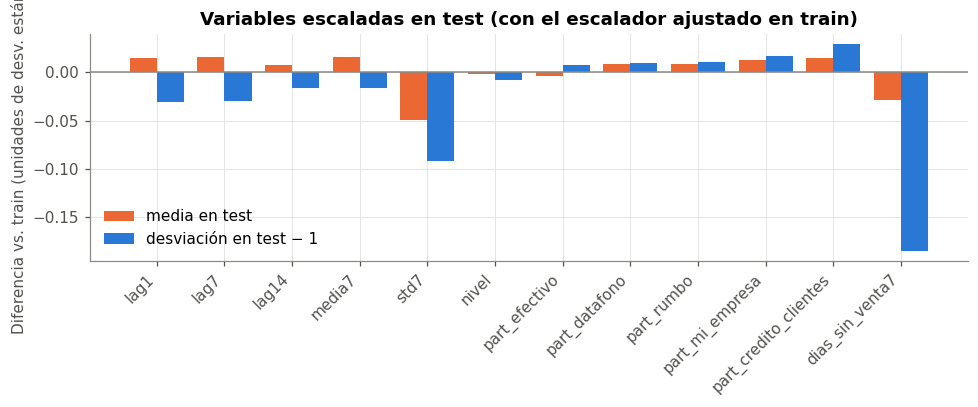

In [8]:
# festivo queda fuera: en test no hay festivos, así que es constante
graf = ver.drop(index="festivo")
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(graf))
ax.bar(x - 0.2, graf["media test"], width=0.4, color=NARANJA, label="media en test")
ax.bar(x + 0.2, graf["desv. test"] - 1, width=0.4, color=AZUL, label="desviación en test − 1")
ax.axhline(0, color=GRIS, lw=1)
ax.set_xticks(x)
ax.set_xticklabels(graf.index, rotation=45, ha="right")
ax.set_title("Variables escaladas en test (con el escalador ajustado en train)")
ax.set_ylabel("Diferencia vs. train (unidades de desv. estándar)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Interpretación

En train, todas las variables numéricas quedan con media 0 y desviación 1, como debe ser. En test se alejan un poco de 0 y 1. Eso demuestra que el escalador **no usó test** y además mide cuánto se parece septiembre a julio–agosto:

- Las variables de nivel y las participaciones cambian menos de 0,05 desviaciones en media: **no hay cambio de distribución** importante entre train y test.
- `std7` y `dias_sin_venta7` tienen menos dispersión en test (desviaciones de 0,91 y 0,81): septiembre tuvo algo menos de días sin venta y de volatilidad.
- `festivo` (fuera de la figura) es constante en test porque no hay festivos: su media escalada es −0,25 y su desviación 0. Su coeficiente no afecta ninguna predicción de test.

```{note}
**Resumen del preprocesamiento.** Se pasa de un panel de 37 828 filas a una matriz de diseño de **19 columnas** (13 numéricas + 6 del día de la semana), con ~22 mil filas de train y ~9 mil de test. Todo paso que aprende de los datos está dentro del Pipeline y se reajusta en cada fold de la validación cruzada.
```